In [8]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as pl
import seaborn as sns
import sys
from tqdm import tqdm
from pathlib import Path

import warnings
warnings.filterwarnings("ignore")

sys.path.insert(1, "/Users/peidli/work/utils/shrimpy/")
import shrimpy as sh

In [9]:
file = Path('/Users/peidli/work/data/scperturb/RNA_new/WesselsSatija2023.h5ad')
adata = sc.read_h5ad(file)

# Count QC

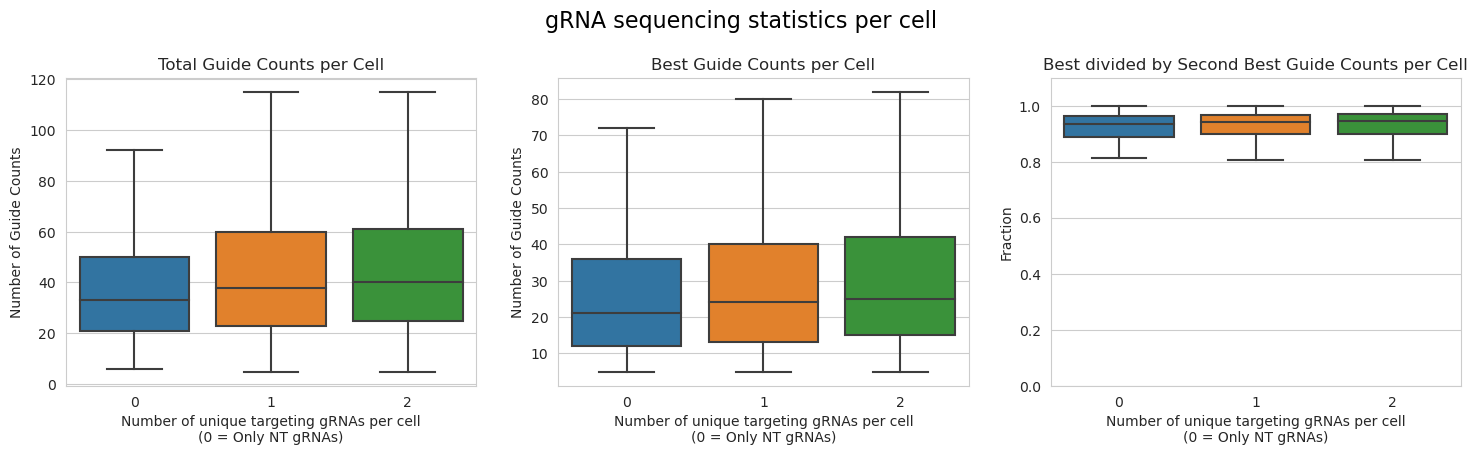

In [6]:
with sns.axes_style('whitegrid'):
    fig, axs = pl.subplots(1, 3, figsize=(6*3, 4), sharex=True, sharey=False)
ax = axs[0]
sns.boxplot(x='nperts', y='nCount_GUIDE', data=adata.obs, showfliers=False, ax=ax, hue="nperts", dodge=False)
ax.set_title('Total Guide Counts per Cell')
ax.set_ylabel('Number of Guide Counts')

ax = axs[1]
sns.boxplot(x='nperts', y='UMI.g1', data=adata.obs, showfliers=False, ax=ax, hue="nperts", dodge=False)
ax.set_title('Best Guide Counts per Cell')
ax.set_ylabel('Number of Guide Counts')

ax = axs[2]
sns.boxplot(x='nperts', y='fraction.g1.over.g2', data=adata.obs, showfliers=False, ax=ax, hue="nperts", dodge=False)
ax.set_title('Best divided by Second Best Guide Counts per Cell')
ax.set_ylabel('Fraction')
ax.set_ylim(0, 1.1)

for ax in axs:
    ax.set_xlabel('Number of unique targeting gRNAs per cell\n(0 = Only NT gRNAs)')
    ax.legend([],[], frameon=False)

pl.suptitle('gRNA sequencing statistics per cell', fontsize=16, y=1.05)
pl.show()

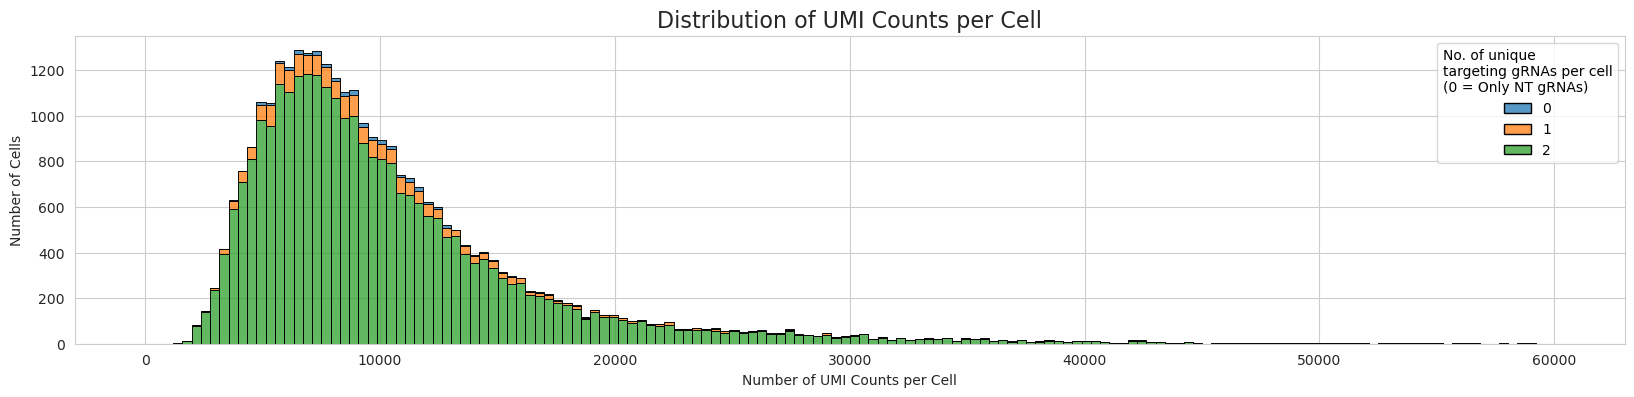

In [10]:
with sns.axes_style('whitegrid'):
    fig, ax = pl.subplots(1, 1, figsize=(20, 4))
hist = sns.histplot(data=adata.obs, x='ncounts', ax=ax, binrange=(0, 60000), hue='nperts', multiple='stack', palette='tab10')
ax.set_xlabel('Number of UMI Counts per Cell')
ax.set_ylabel('Number of Cells')
ax.get_legend().set_title('No. of unique\ntargeting gRNAs per cell\n(0 = Only NT gRNAs)')
ax.set_title('Distribution of UMI Counts per Cell', fontsize=16)
pl.show()

# Collateral Activity

In [11]:
from statannotations.Annotator import Annotator

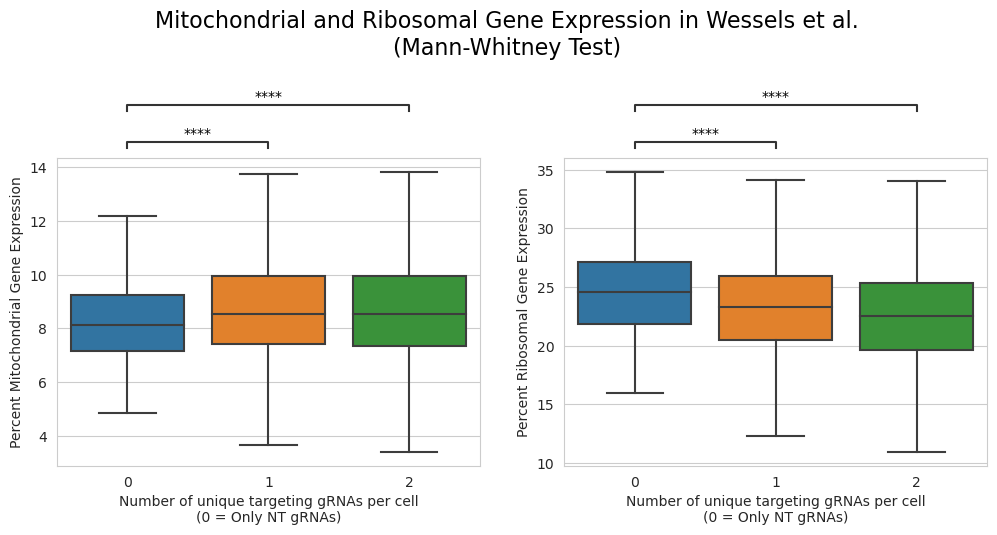

In [12]:
with sns.axes_style('whitegrid'):
    fig, axs = pl.subplots(1, 2, figsize=(6*2,4))

ax = axs[0]
sns.boxplot(x='nperts', y='percent_mito', data=adata.obs, showfliers=False, ax=ax)
ax.set_ylabel('Percent Mitochondrial Gene Expression')
ax.set_xlabel('Number of unique targeting gRNAs per cell\n(0 = Only NT gRNAs)')

annotator = Annotator(ax, [(0, 1), (0,2)], data=adata.obs, x='nperts', y='percent_mito', verbose=0)
annotator.configure(test='Mann-Whitney', text_format='star', loc='outside', show_test_name=True)
annotator.apply_and_annotate()

ax = axs[1]
sns.boxplot(x='nperts', y='percent_ribo', data=adata.obs, showfliers=False, ax=ax)
ax.set_ylabel('Percent Ribosomal Gene Expression')
ax.set_xlabel('Number of unique targeting gRNAs per cell\n(0 = Only NT gRNAs)')

annotator = Annotator(ax, [(0, 1), (0,2)], data=adata.obs, x='nperts', y='percent_ribo', verbose=0)
annotator.configure(test='Mann-Whitney', text_format='star', loc='outside', show_test_name=True)
annotator.apply_and_annotate()

pl.suptitle('Mitochondrial and Ribosomal Gene Expression in Wessels et al.\n(Mann-Whitney Test)', fontsize=16, y=1.25)

pl.show()

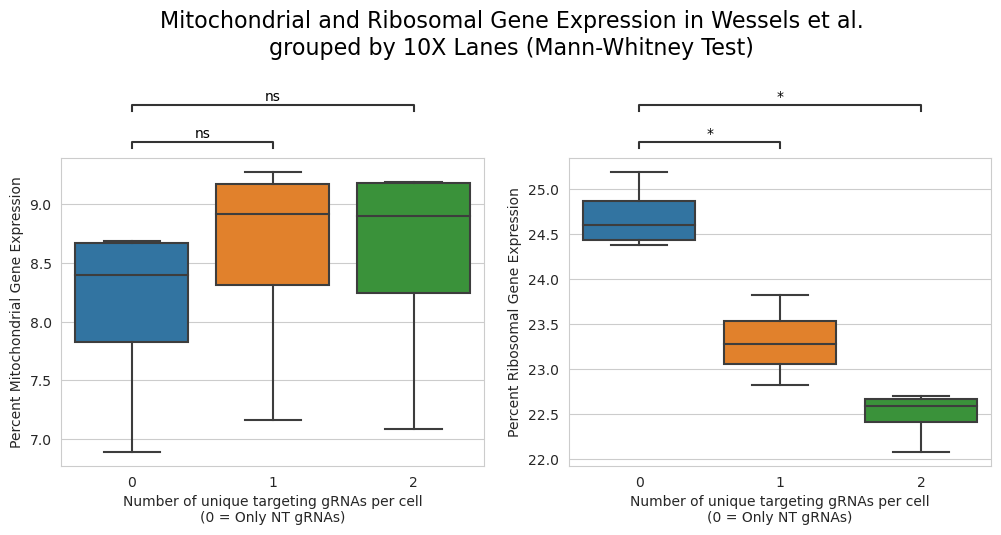

In [13]:
with sns.axes_style('whitegrid'):
    fig, axs = pl.subplots(1, 2, figsize=(6*2,4))

ax = axs[0]
df = adata.obs.groupby(['nperts', '10X_lane']).mean()['percent_mito'].reset_index()
sns.boxplot(x='nperts', y='percent_mito', data=df, showfliers=False, ax=ax)
ax.set_ylabel('Percent Mitochondrial Gene Expression')
ax.set_xlabel('Number of unique targeting gRNAs per cell\n(0 = Only NT gRNAs)')

annotator = Annotator(ax, [(0, 1), (0,2)], data=df, x='nperts', y='percent_mito', verbose=0)
annotator.configure(test='Mann-Whitney', text_format='star', loc='outside', show_test_name=True)
annotator.apply_and_annotate()

ax = axs[1]
df = adata.obs.groupby(['nperts', '10X_lane']).mean()['percent_ribo'].reset_index()
sns.boxplot(x='nperts', y='percent_ribo', data=df, showfliers=False, ax=ax)
ax.set_ylabel('Percent Ribosomal Gene Expression')
ax.set_xlabel('Number of unique targeting gRNAs per cell\n(0 = Only NT gRNAs)')

annotator = Annotator(ax, [(0, 1), (0,2)], data=df, x='nperts', y='percent_ribo', verbose=0)
annotator.configure(test='Mann-Whitney', text_format='star', loc='outside', show_test_name=True)
annotator.apply_and_annotate()

pl.suptitle('Mitochondrial and Ribosomal Gene Expression in Wessels et al.\ngrouped by 10X Lanes (Mann-Whitney Test)', fontsize=16, y=1.25)

pl.show()

# Target Knockdown Efficiency

In [10]:
s=[x.split('_') for x in adata.obs.perturbation]
unique_targets =  np.unique([c for b in s for c in b])

In [11]:
unique_targets_found = list(unique_targets[np.isin(unique_targets, adata.var.index)])

In [17]:
df = sh.extract_df(adata, unique_targets_found+["perturbation"])

In [43]:
A = {}
df = sh.extract_df(adata, unique_targets_found+["perturbation"])
for g in tqdm(unique_targets_found):
    mask = df.perturbation.str.contains(g)
    mask_precise = df.perturbation == g
    mask_c = df.perturbation.str.contains("control")
    A[g] = [df[mask][g].mean(), df[mask_precise][g].mean(), df[mask_c][g].mean()]

100%|██████████| 27/27 [00:00<00:00, 606.10it/s]


In [48]:
sdf = pd.DataFrame(A, index=["targeted (gene is among the targets)", "targeted (gene is only target)", "Non-targeting"]).T

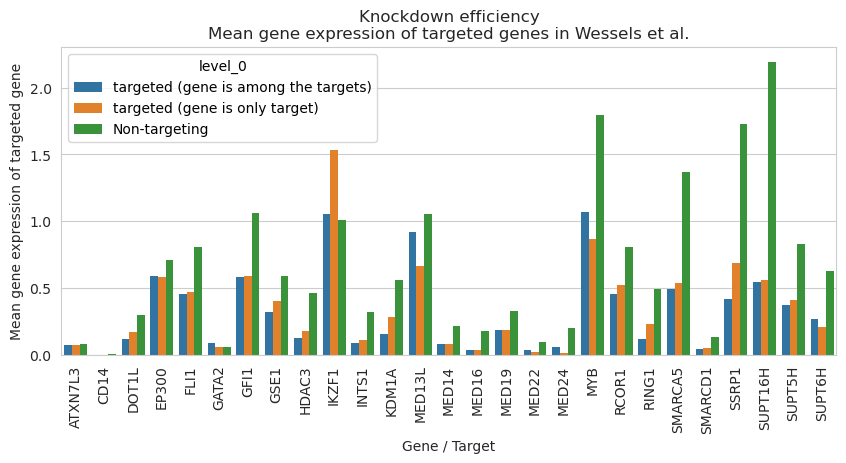

In [50]:
with sns.axes_style('whitegrid'):
    fig, ax = pl.subplots(1, 1, figsize=(10, 4))
sns.barplot(data=sdf.unstack().reset_index(), x='level_1', y=0, hue='level_0', ax=ax)
pl.xticks(rotation=90)
ax.set_ylabel('Mean gene expression of targeted gene')
ax.set_xlabel('Gene / Target')
ax.set_title('Knockdown efficiency\nMean gene expression of targeted genes in Wessels et al.')
pl.show()